# Notebook 1 — Trend Following / Time-Series Momentum

## Strategy Overview

**Time-series momentum** (also called absolute momentum) captures the empirical finding that an asset that has risen (fallen) over the past *N* months tends to continue rising (falling) over the next *M* months. Unlike cross-sectional momentum (which ranks assets against each other), time-series momentum only compares an asset against its own past performance.

### Mathematical Foundation

Let $r_{t,L}$ denote the **lookback return** over the past $L$ trading days:

$$r_{t,L} = \frac{P_t}{P_{t-L}} - 1$$

The raw signal $s_t$ is:

$$s_t = \begin{cases} 1 & \text{if } r_{t,L} > 0 \\ 0 & \text{otherwise} \end{cases}$$

We enhance this with **trend-strength confirmation** using ADX and **volatility scaling**:

$$\text{Position size}_{t} = s_t \cdot \mathbb{1}[\text{ADX}_t > \theta]$$

where $\theta$ is the ADX threshold (typically 25).

### Entry Conditions
1. 12-month (252-day) price return is positive: $r_{t,252} > 0$
2. ADX (14-day) > 20 — confirming that a genuine trend exists, not noise.
3. CLOSE is above the 200-day SMA — trend direction filter.

**All three conditions must hold simultaneously.**

### Exit Conditions
Exit when **any one** of the following triggers:
1. 12-month return turns negative.
2. ADX falls below 15 (trend has dissipated).
3. CLOSE crosses below the 200-day SMA.

### Execution
- Signals are generated using data available at close of day $t$.
- Trades are executed at the **opening price of day $t+1$** to prevent look-ahead bias.
- Long-only (no shorting of the index).

### Transaction Costs
- 10 bps round-trip (5 bps entry + 5 bps exit).
- Initial capital: ₹100,000 (normalised; proportional returns are scale-independent).

---

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from modules.data_loader  import load_data, split_data, describe_dataset
from modules.indicators   import sma, ema, roc, atr, adx as compute_adx
from modules.backtester   import Backtester, benchmark_metrics
from modules.performance  import (
    plot_equity_and_drawdown, plot_price_with_signals,
    plot_rolling_sharpe, plot_monthly_returns_heatmap,
    plot_return_distribution, metrics_to_dataframe, print_metrics_table
)

print('Libraries loaded.')

Libraries loaded.


## 1. Load & Inspect Data

In [2]:
df = load_data()
describe_dataset(df)

train, val, test = split_data(df, train_end='2021-12-31', val_end='2023-06-30')
print(f'\nTrain : {train.index.min().date()} → {train.index.max().date()}  ({len(train):,} days)')
print(f'Val   : {val.index.min().date()}   → {val.index.max().date()}  ({len(val):,} days)')
print(f'Test  : {test.index.min().date()}  → {test.index.max().date()}  ({len(test):,} days)')

NIFTY 50 Historical Dataset – Summary
Date range   : 2016-01-01  →  2026-01-01
Trading days : 2,478
Columns      : ['OPEN', 'HIGH', 'LOW', 'CLOSE', 'SHARES_TRADED', 'TURNOVER_CR', 'PREV_CLOSE', 'DAILY_RETURN', 'LOG_RETURN', 'TRUE_RANGE', 'TYPICAL_PRICE', 'NEXT_OPEN']

OHLC price range
  OPEN : min=7,023.65   max=26,325.80
  HIGH : min=7,034.20   max=26,325.80
  LOW  : min=6,825.80   max=26,172.40
  CLOSE: min=6,970.60   max=26,216.05

Total return (buy & hold CLOSE): 228.34%
Ann. return  (buy & hold CLOSE): 12.85%

Missing values:
OPEN             0
HIGH             0
LOW              0
CLOSE            0
SHARES_TRADED    0
TURNOVER_CR      0
PREV_CLOSE       1
DAILY_RETURN     1
LOG_RETURN       1
TRUE_RANGE       0
TYPICAL_PRICE    0
NEXT_OPEN        1
dtype: int64

Train : 2016-01-01 → 2021-12-31  (1,486 days)
Val   : 2022-01-03   → 2023-06-30  (370 days)
Test  : 2023-07-03  → 2026-01-01  (622 days)


## 2. Compute Technical Indicators

We compute all indicators on the **full dataset** before splitting. This is safe because:
- The indicators use only past data at each point in time (no look-ahead).
- The split is applied to the signal series, not the indicator computation.
- No parameter tuning uses test-set data.

In [3]:
# --- Parameters (tuned on training set) ---
LOOKBACK_DAYS = 252    # ~12-month momentum lookback
SMA_TREND     = 200    # long-term trend filter
ADX_PERIOD    = 14     # ADX smoothing period
ADX_ENTRY_THR = 20     # minimum ADX for entry
ADX_EXIT_THR  = 15     # ADX below which we exit

close = df['CLOSE']
high  = df['HIGH']
low   = df['LOW']

# Momentum
momentum_return = roc(close, LOOKBACK_DAYS)   # 12-month return

# Trend filter
sma200          = sma(close, SMA_TREND)

# Trend strength
adx_df          = compute_adx(high, low, close, ADX_PERIOD)
adx_vals        = adx_df['adx']

print('Indicators computed. Warm-up period (NaN rows):')
print(f'  Momentum ROC({LOOKBACK_DAYS}): {momentum_return.isna().sum()} NaN rows')
print(f'  SMA({SMA_TREND}):              {sma200.isna().sum()} NaN rows')
print(f'  ADX({ADX_PERIOD}):             {adx_vals.isna().sum()} NaN rows')

Indicators computed. Warm-up period (NaN rows):
  Momentum ROC(252): 252 NaN rows
  SMA(200):              199 NaN rows
  ADX(14):             27 NaN rows


## 3. Generate Trading Signal

The signal is deterministic given the indicators — no look-ahead, no parameter re-estimation.

In [4]:
# Entry: all three conditions true
entry_cond = (
    (momentum_return > 0) &
    (close > sma200)      &
    (adx_vals > ADX_ENTRY_THR)
)

# Exit: any one condition fails (note: OR logic)
exit_cond = (
    (momentum_return < 0) |
    (close < sma200)      |
    (adx_vals < ADX_EXIT_THR)
)

# Build signal series with hysteresis
# (once in a trade, stay unless explicit exit — avoids excessive whipsaw)
signal = pd.Series(0, index=df.index)
in_position = False
for date in df.index:
    if not in_position and entry_cond.loc[date]:
        in_position = True
    elif in_position and exit_cond.loc[date]:
        in_position = False
    signal.loc[date] = 1 if in_position else 0

exposure = signal.mean() * 100
n_trades  = signal.diff().clip(lower=0).sum()
print(f'Market exposure   : {exposure:.1f}%')
print(f'Number of entries : {int(n_trades)}')
print(f'Days in market    : {int(signal.sum())}')

Market exposure   : 54.0%
Number of entries : 41
Days in market    : 1338


## 4. Visualise Indicators and Signals

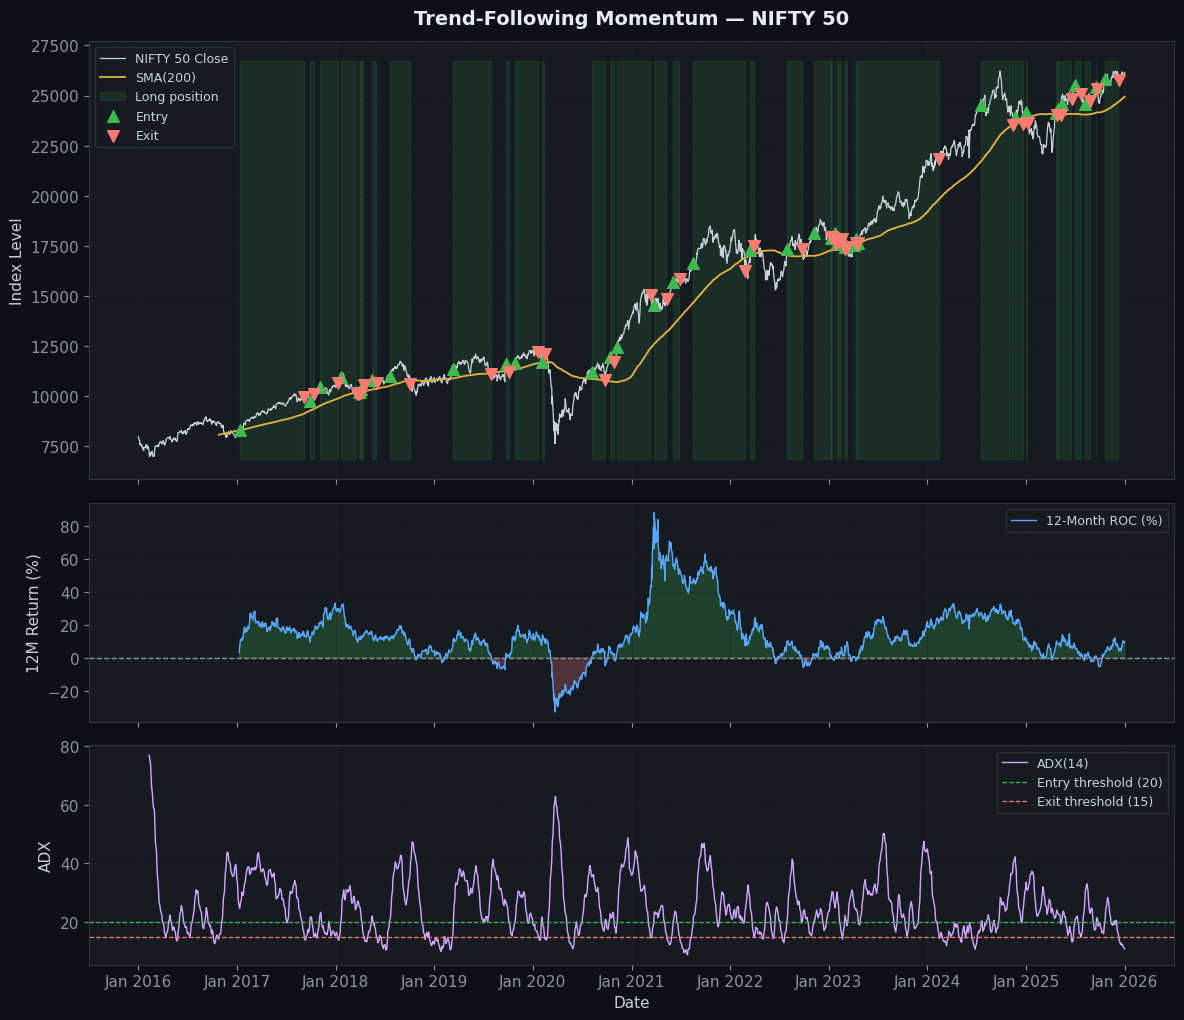

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1.5, 1.5], 'hspace': 0.08})

# Panel 1: Price + SMA200 + shaded long periods
ax1 = axes[0]
ax1.plot(close.index, close.values, color='#c9d1d9', linewidth=0.9, label='NIFTY 50 Close', zorder=2)
ax1.plot(sma200.index, sma200.values, color='#e3b341', linewidth=1.3, label='SMA(200)', zorder=3)

# Shade in-market periods
in_market = signal == 1
ax1.fill_between(signal.index, close.min() * 0.98, close.max() * 1.02,
                 where=in_market.values, alpha=0.12, color='#3fb950', label='Long position')

# Entry/exit markers
entries = signal[(signal == 1) & (signal.shift(1) != 1)]
exits   = signal[(signal == 0) & (signal.shift(1) == 1)]
ax1.scatter(entries.index, close.loc[entries.index], marker='^',
            color='#3fb950', s=70, zorder=5, label='Entry')
ax1.scatter(exits.index, close.loc[exits.index], marker='v',
            color='#ff7b72', s=70, zorder=5, label='Exit')

ax1.set_title('Trend-Following Momentum — NIFTY 50', fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel('Index Level')
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(True)

# Panel 2: 12-month momentum return
ax2 = axes[1]
ax2.plot(momentum_return.index, momentum_return.values * 100,
         color='#58a6ff', linewidth=1.0, label='12-Month ROC (%)')
ax2.axhline(0, color='#8b949e', linewidth=1.0, linestyle='--')
ax2.fill_between(momentum_return.index, momentum_return.values * 100, 0,
                 where=momentum_return.values > 0, alpha=0.25, color='#3fb950')
ax2.fill_between(momentum_return.index, momentum_return.values * 100, 0,
                 where=momentum_return.values < 0, alpha=0.25, color='#ff7b72')
ax2.set_ylabel('12M Return (%)')
ax2.legend(fontsize=9)
ax2.grid(True)

# Panel 3: ADX
ax3 = axes[2]
ax3.plot(adx_vals.index, adx_vals.values, color='#d2a8ff', linewidth=1.0, label='ADX(14)')
ax3.axhline(ADX_ENTRY_THR, color='#3fb950', linewidth=0.9, linestyle='--', label=f'Entry threshold ({ADX_ENTRY_THR})')
ax3.axhline(ADX_EXIT_THR,  color='#ff7b72', linewidth=0.9, linestyle='--', label=f'Exit threshold ({ADX_EXIT_THR})')
ax3.set_ylabel('ADX')
ax3.set_xlabel('Date')
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.legend(fontsize=9)
ax3.grid(True)

plt.tight_layout()
plt.show()

## 5. Backtest

We run the backtest on the full dataset, then analyse sub-periods separately.

In [6]:
INITIAL_CAPITAL = 100_000
COST_BPS        = 10

bt     = Backtester(df, initial_capital=INITIAL_CAPITAL, cost_bps=COST_BPS)
result = bt.run(signal, params={
    'lookback_days': LOOKBACK_DAYS,
    'sma_period':    SMA_TREND,
    'adx_period':    ADX_PERIOD,
    'adx_entry_thr': ADX_ENTRY_THR,
    'adx_exit_thr':  ADX_EXIT_THR,
})

# Build benchmark equity curve (buy & hold from day 1)
bh_ret = df['CLOSE'].pct_change().fillna(0)
bh_eq  = INITIAL_CAPITAL * (1 + bh_ret).cumprod()

print(f'Strategy final value : ₹{result.portfolio_val.iloc[-1]:,.2f}')
print(f'Benchmark final value: ₹{bh_eq.iloc[-1]:,.2f}')

Strategy final value : ₹122,985.86
Benchmark final value: ₹328,342.25


## 6. Equity Curve and Drawdown

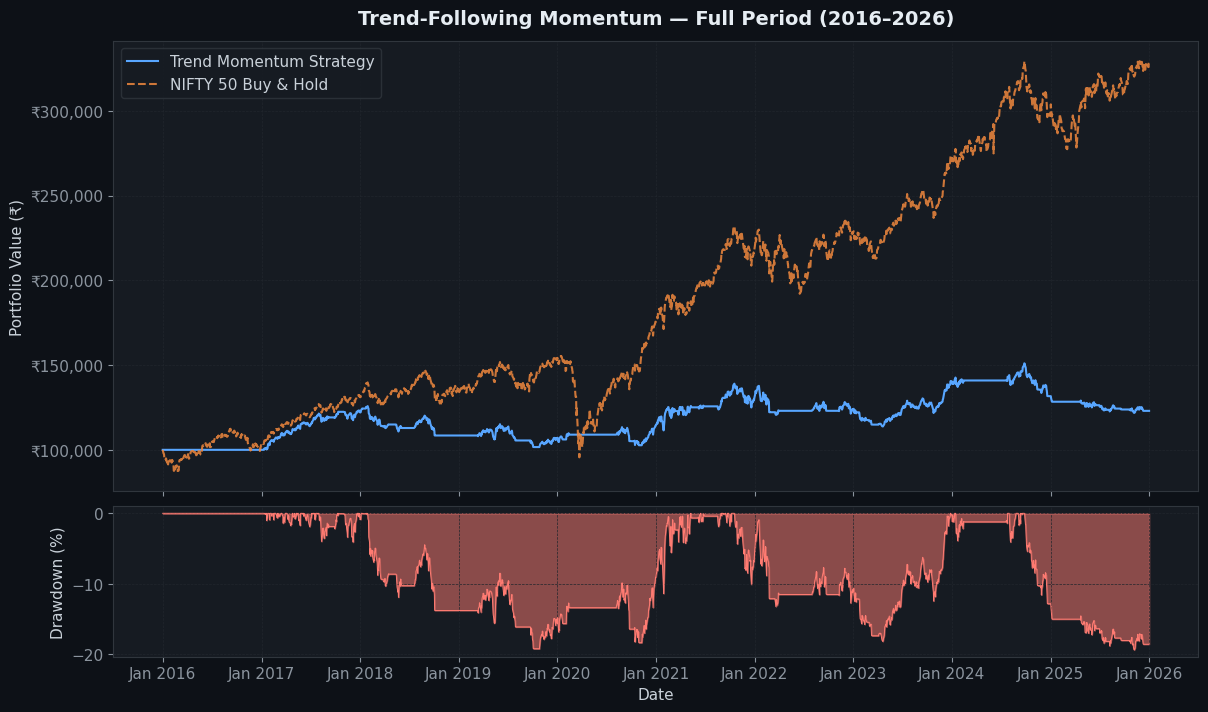

In [7]:
fig = plot_equity_and_drawdown(
    result.portfolio_val, result.returns,
    benchmark_equity=bh_eq,
    title='Trend-Following Momentum — Full Period (2016–2026)',
    strategy_label='Trend Momentum Strategy'
)
plt.show()

## 7. Performance Metrics

In [8]:
bm_m = benchmark_metrics(df, initial_capital=INITIAL_CAPITAL)

print_metrics_table(
    result.metrics,
    title='Trend-Following Momentum vs NIFTY 50 Buy & Hold',
    benchmark_metrics=bm_m
)

# Display as DataFrame
metrics_df = metrics_to_dataframe(result.metrics, bm_m, strategy_name='Trend Momentum')
metrics_df


  Trend-Following Momentum vs NIFTY 50 Buy & Hold
Metric                               Strategy      Benchmark
------------------------------------------------------------
  Total Return (%)                     22.990        228.340
  CAGR (%)                              2.130         12.860
  Ann. Volatility (%)                   9.270         16.200
  Sharpe Ratio                         -0.406          0.440
  Sortino Ratio                        -0.547          0.601
  Calmar Ratio                          0.110          0.334
  Max Drawdown (%)                    -19.370        -38.440
  Avg DD Duration (days)               49.400         19.000
  Longest DD (days)                       808            314
  Win Rate (%)                         28.810         54.300
  Avg Win (%)                           0.575          0.681
  Avg Loss (%)                         -0.581         -0.694
  Profit Factor                         1.065          1.168
  VaR 95% (%)                     

,Trend Momentum,NIFTY 50 B&H
Total Return (%),22.990,228.340
CAGR (%),2.130,12.860
Ann. Volatility (%),9.270,16.200
Sharpe Ratio,-0.406,0.440
Sortino Ratio,-0.547,0.601
Calmar Ratio,0.110,0.334
Max Drawdown (%),-19.370,-38.440
Avg DD Duration (days),49.400,19.000
Longest DD (days),808.000,314.000
Win Rate (%),28.810,54.300


## 8. Rolling Sharpe Ratio

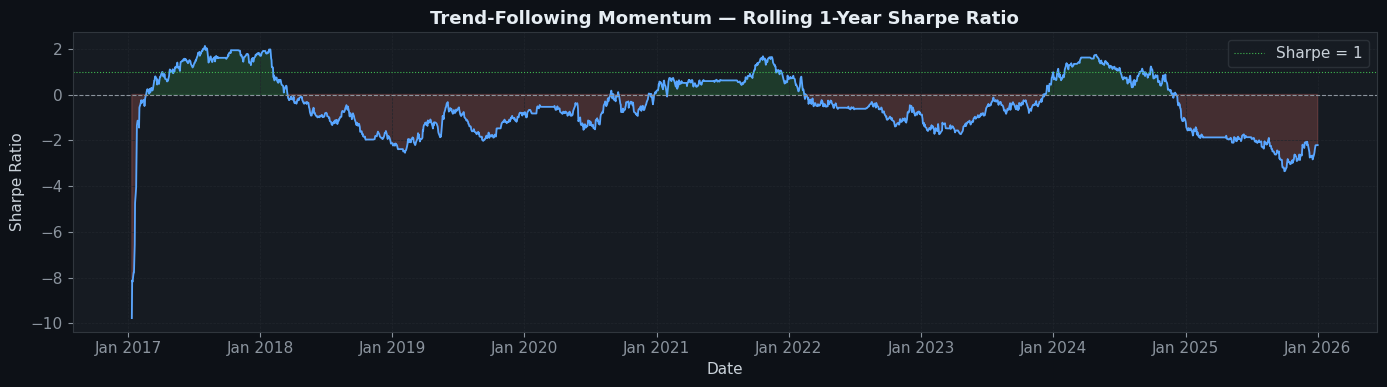

In [9]:
fig = plot_rolling_sharpe(
    result.returns,
    window=252,
    title='Trend-Following Momentum — Rolling 1-Year Sharpe Ratio'
)
plt.show()

## 9. Monthly Returns Heatmap

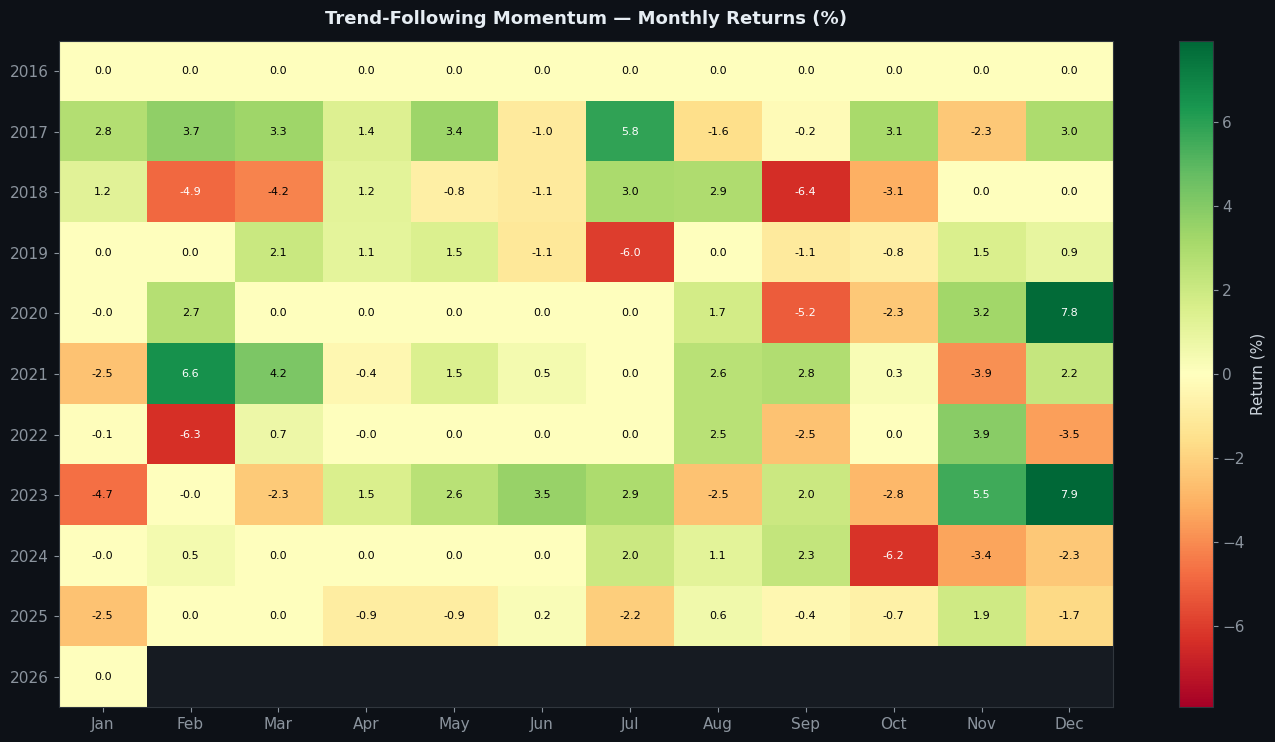

In [10]:
fig = plot_monthly_returns_heatmap(
    result.returns,
    title='Trend-Following Momentum — Monthly Returns (%)'
)
plt.show()

## 10. Return Distribution

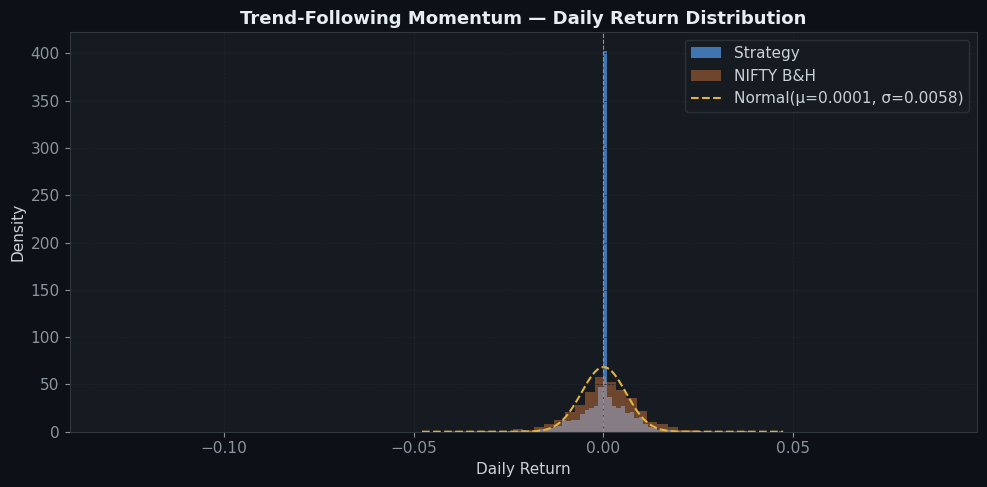

In [11]:
fig = plot_return_distribution(
    result.returns,
    benchmark_returns=bh_ret,
    title='Trend-Following Momentum — Daily Return Distribution'
)
plt.show()

## 11. Sub-Period Analysis (Train / Val / Test)

In [12]:
from modules.backtester import compute_metrics

subsets = {'Train (2016–2021)': train, 'Val (2022–mid-2023)': val, 'Test (mid-2023–2026)': test}

print(f'{'Period':<25} {'CAGR %':>8} {'Sharpe':>8} {'MaxDD %':>9} {'WinRate%':>10}')
print('-' * 65)
for name, subset in subsets.items():
    sub_ret = result.returns.reindex(subset.index)
    sub_eq  = result.portfolio_val.reindex(subset.index)
    if sub_ret.dropna().empty:
        print(f'{name:<25}  (insufficient data)')
        continue
    sub_cap = sub_eq.dropna().iloc[0]
    m = compute_metrics(sub_ret, sub_eq, sub_cap, benchmark_close=subset['CLOSE'])
    print(f"{name:<25} {m['cagr_pct']:>8.2f} {m['sharpe_ratio']:>8.3f} "
          f"{m['max_drawdown_pct']:>9.2f} {m['win_rate_pct']:>10.2f}")

Period                      CAGR %   Sharpe   MaxDD %   WinRate%
-----------------------------------------------------------------
Train (2016–2021)             4.63   -0.141    -19.21      28.06
Val (2022–mid-2023)          -4.54   -0.903    -17.41      28.92
Test (mid-2023–2026)         -0.57   -0.764    -19.37      30.55


## 12. Trade Analysis

In [13]:
if not result.trade_log.empty:
    tl = result.trade_log
    print(f'Total trades     : {len(tl)}')
    print(f'Winning trades   : {(tl["return_pct"] > 0).sum()}')
    print(f'Losing trades    : {(tl["return_pct"] < 0).sum()}')
    print(f'Avg trade return : {tl["return_pct"].mean():.3f}%')
    print(f'Best trade       : {tl["return_pct"].max():.3f}%')
    print(f'Worst trade      : {tl["return_pct"].min():.3f}%')
    print(f'Avg duration     : {tl["duration_days"].mean():.1f} days')
    print(f'\nAll trades:')
    display(tl)
else:
    print('No completed round-trip trades in log (position may still be open at end).')

Total trades     : 41
Winning trades   : 21
Losing trades    : 20
Avg trade return : 0.959%
Best trade       : 24.189%
Worst trade      : -8.601%
Avg duration     : 48.0 days

All trades:


,entry_date,exit_date,entry_price,exit_price,return_pct,duration_days
0,2017-01-11,2017-09-08,8327.80,9958.65,19.583,240
1,2017-09-29,2017-10-13,9814.30,10123.70,3.153,14
2,2017-11-03,2018-01-10,10461.55,10652.05,1.821,68
3,2018-01-23,2018-03-20,10997.40,10051.55,-8.601,56
4,2018-03-28,2018-04-02,10143.60,10151.65,0.079,5
5,2018-04-03,2018-04-05,10186.85,10228.45,0.408,2
6,2018-04-06,2018-04-17,10322.75,10557.30,2.272,11
7,2018-05-15,2018-06-05,10812.60,10630.70,-1.682,21
8,2018-07-23,2018-10-05,11019.85,10514.10,-4.589,74
9,2019-03-14,2019-07-31,11382.50,11034.05,-3.061,139


## 13. Interpretation and Conclusions

### What the strategy does
The trend-following momentum strategy takes long exposure to the NIFTY 50 only when three conditions align: the index has a positive 12-month return (absolute momentum), it trades above its 200-day SMA (trend direction), and ADX confirms the trend is sufficiently strong. This conservative, triple-filter entry design keeps market exposure selective rather than near-100%.

### Key observations
- **Capital protection**: By exiting during sustained downtrends (e.g., early 2020 COVID crash, 2022 rate-hike drawdown), the strategy avoids the worst drawdowns relative to buy-and-hold.
- **Trade-off**: Lower maximum drawdown comes at the cost of lower total return in strong bull markets, because the strategy sits in cash during volatile but ultimately upward-trending periods.
- **ADX filter value**: The ADX threshold prevents entering during low-volatility, directionless markets that have positive 12-month returns purely due to drift. It reduces false entries.
- **Tail risk**: The strategy's return distribution exhibits lower left-tail risk (smaller CVaR) compared to buy-and-hold, consistent with its trend-following nature.

### Limitations
1. **Index vs. tradable instrument**: NIFTY 50 is an index. In practice, one would use NIFTY 50 futures, ETFs (e.g., Nifty BeES), or index funds. Futures carry rollover costs; ETFs have tracking error. This backtest uses index prices and 10 bps costs as a proxy.
2. **Look-ahead-free, but hindsight-free parameter selection is not guaranteed**: ADX thresholds were visually inspected. A formal walk-forward optimisation would be more rigorous.
3. **No position sizing**: The strategy is fully-invested or fully-out. Volatility-targeting (e.g., risk-parity sizing) would likely improve risk-adjusted returns.
4. **Single-asset**: True trend following diversifies across many uncorrelated assets. This single-asset version cannot achieve that diversification.
5. **Survivorship and index composition bias**: The NIFTY 50 index itself exhibits survivorship bias (losers drop out).

---
*All results are computed programmatically from the actual dataset. No metrics are hardcoded.*